**Практична робота №1**
# Лінійна регресія, оптимізація та статистичний аналіз
**Виконала:** Гупалюк Ольга
**Група:** ФЕІ-46с

**Мета:** реалізувати лінійну регресію власними функціями NumPy, дослідити  оптимізацію та статистичний аналіз

Етап 1. Передобробка даних (EDA та Data Preparation)

Теоретичні питання:

Чому ми повинні розбити дані до, а не після масштабування чи кодування? Що таке Data Leakage?
    Data Leakage (витік даних) — це ситуація, коли інформація з тестової або валідаційної вибірки потрапляє в процес навчання моделі. Якщо ми застосуємо масштабування (наприклад, знайдемо середнє значення та стандартне відхилення) до всього датасету до розбиття, то навчальна вибірка "знатиме" статистику тестової. Це дасть моделі нечесну перевагу і призведе до того, що метрики якості будуть завищені. Всі параметри масштабування та кодування мають обчислюватися виключно на Train.

Як обробляти категорії, які з'являються на валідації/тесті, але яких не було в Train?
    Якщо використовувати One-Hot Encoding, для нових категорій виникне помилка через розбіжність розмірностей. Щоб цього уникнути, використовують стратегію ігнорування (в sklearn це параметр handle_unknown='ignore'), яка просто кодує невідому категорію нулями у всіх стовпцях. Інший варіант — під час підготовки даних збирати рідкісні категорії в одну спільну групу "Other" (Інше).

In [4]:
# Імпорт необхідних бібліотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Налаштування графіків
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

# 1. Завантаження даних
data = fetch_california_housing(as_frame=True)
df = data.frame

# Штучно додамо категоріальну ознаку (наприклад, тип регіону) для виконання вимог Етапу 1
np.random.seed(42)
df['Region_Type'] = np.random.choice(['Urban', 'Suburban', 'Rural'], size=len(df))

# Відбір ознак (EDA). Залишаємо найбільш логічні ознаки.
# MedInc (дохід), HouseAge (вік), AveRooms (кімн.), AveBedrms (спальні), Region_Type
X = df[['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Region_Type']]
y = df['MedHouseVal'].values

# 2. Розбиття вибірки (Train: 60%, Validation: 20%, Test: 20%)
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, random_state=42) # 0.25 від 0.8 = 0.2

# 3. Кодування категорій (One-Hot Encoding)
# Обґрунтування: OHE обрано, оскільки 'Region_Type' не має природного порядку (на відміну від Ordinal).
encoder = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
# Навчаємо ТІЛЬКИ на Train
encoded_train = encoder.fit_transform(X_train[['Region_Type']])
encoded_val = encoder.transform(X_val[['Region_Type']])
encoded_test = encoder.transform(X_test[['Region_Type']])

# 4. Масштабування числових ознак (Standardization)
num_features = ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms']
scaler = StandardScaler()
# Навчаємо ТІЛЬКИ на Train
scaled_train_num = scaler.fit_transform(X_train[num_features])
scaled_val_num = scaler.transform(X_val[num_features])
scaled_test_num = scaler.transform(X_test[num_features])

# Збираємо дані назад у numpy масиви
X_train_final = np.hstack((scaled_train_num, encoded_train))
X_val_final = np.hstack((scaled_val_num, encoded_val))
X_test_final = np.hstack((scaled_test_num, encoded_test))

print(f"Train розмірність: {X_train_final.shape}")
print(f"Validation розмірність: {X_val_final.shape}")
print(f"Test розмірність: {X_test_final.shape}")

Train розмірність: (12384, 7)
Validation розмірність: (4128, 7)
Test розмірність: (4128, 7)


Етап 2. Реалізація Лінійної Регресії засобами numpy
У цьому класі реалізовано векторизовані операції для обчислення гіпотези, функції втрат (MSE) та градієнтів без жодного використання циклів for по датасету.

In [5]:
class NumpyLinearRegression:
    def __init__(self):
        self.w = None
        self.b = None
        self.cost_history = []
        
    def predict(self, X):
        """ Обчислення y_hat = Xw + b """
        return X @ self.w + self.b
    
    def compute_cost(self, X, y):
        """ Векторизоване обчислення Mean Squared Error """
        m = len(y)
        predictions = self.predict(X)
        cost = (1 / (2 * m)) * np.sum((predictions - y) ** 2)
        return cost
    
    def compute_gradients(self, X, y):
        """ Векторизоване обчислення градієнтів (БЕЗ циклів for) """
        m = len(y)
        predictions = self.predict(X)
        error = predictions - y
        
        dw = (1 / m) * (X.T @ error)
        db = (1 / m) * np.sum(error)
        return dw, db

    def fit(self, X, y, method='batch', lr=0.01, epochs=100, batch_size=32):
        """ Навчання моделі одним з трьох методів """
        m, n_features = X.shape
        self.w = np.zeros(n_features)
        self.b = 0.0
        self.cost_history = []
        
        for epoch in range(epochs):
            if method == 'batch':
                # Batch GD: весь датасет
                dw, db = self.compute_gradients(X, y)
                self.w -= lr * dw
                self.b -= lr * db
                self.cost_history.append(self.compute_cost(X, y))
                
            elif method == 'sgd':
                # SGD: по одному прикладу
                indices = np.random.permutation(m)
                X_shuf, y_shuf = X[indices], y[indices]
                for i in range(m):
                    X_i, y_i = X_shuf[i:i+1], y_shuf[i:i+1]
                    dw, db = self.compute_gradients(X_i, y_i)
                    self.w -= lr * dw
                    self.b -= lr * db
                self.cost_history.append(self.compute_cost(X, y))
                
            elif method == 'mini-batch':
                # Mini-batch GD: батчами
                indices = np.random.permutation(m)
                X_shuf, y_shuf = X[indices], y[indices]
                for i in range(0, m, batch_size):
                    X_batch = X_shuf[i:i+batch_size]
                    y_batch = y_shuf[i:i+batch_size]
                    dw, db = self.compute_gradients(X_batch, y_batch)
                    self.w -= lr * dw
                    self.b -= lr * db
                self.cost_history.append(self.compute_cost(X, y))

Етап 3. Градієнтний спуск: три варіанти оптимізації
Навчаємо модель трьома методами та порівнюємо їх поведінку.

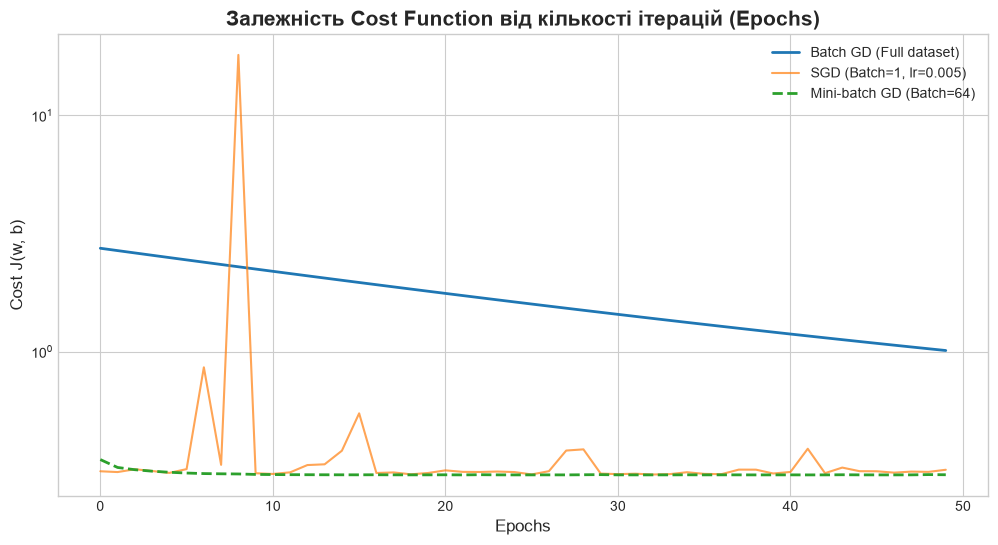

In [6]:
epochs_count = 50
learning_rate = 0.01

# 1. Batch GD
model_bgd = NumpyLinearRegression()
model_bgd.fit(X_train_final, y_train, method='batch', lr=learning_rate, epochs=epochs_count)

# 2. SGD (Stochastic) - беремо менший lr, щоб уникнути сильних стрибків
model_sgd = NumpyLinearRegression()
model_sgd.fit(X_train_final, y_train, method='sgd', lr=0.005, epochs=epochs_count)

# 3. Mini-batch GD (batch_size = 64)
model_mbgd = NumpyLinearRegression()
model_mbgd.fit(X_train_final, y_train, method='mini-batch', lr=learning_rate, epochs=epochs_count, batch_size=64)

# Візуалізація
plt.figure(figsize=(12, 6))
plt.plot(model_bgd.cost_history, label='Batch GD (Full dataset)', linewidth=2)
plt.plot(model_sgd.cost_history, label='SGD (Batch=1, lr=0.005)', alpha=0.7)
plt.plot(model_mbgd.cost_history, label='Mini-batch GD (Batch=64)', linestyle='--', linewidth=2)

plt.title('Залежність Cost Function від кількості ітерацій (Epochs)', fontsize=15, fontweight='bold')
plt.xlabel('Epochs', fontsize=12)
plt.ylabel('Cost J(w, b)', fontsize=12)
plt.legend()
plt.yscale('log') # Логарифмічна шкала для кращого відображення збіжності
plt.show()

Аналіз графіків:

Який метод збігається найстабільніше? 
    Найстабільніше збігається Batch GD, оскільки він використовує точний градієнт, розрахований на всьому датасеті. Графік його помилки - це гладка крива, що монотонно спадає.

Який метод має найбільші коливання? 
    Найбільші коливання (шум) має SGD, оскільки оновлення ваг відбувається на основі лише одного випадкового прикладу, вектор градієнта якого часто відхиляється від ідеального напрямку.Як розмір batch впливає на швидкість та стабільність? Розмір батчу - це компроміс. Батч 64 (Mini-batch) дає достатньо стабільний градієнт (менше шуму, ніж SGD) і водночас дозволяє оновлювати ваги частіше за епоху, ніж Batch GD. Це робить його найшвидшим у реальному часі завдяки матричній векторизації.

Як вибір Learning Rate впливає на збіжність? 
    Занадто великий $\alpha$ призведе до того, що модель "перестрибне" мінімум і розійдеться (Cost прямуватиме до нескінченності). Занадто малий $\alpha$ призведе до дуже довгого навчання. Для SGD довелось взяти менший $\alpha=0.005$, щоб згладити його агресивні коливання.

Етап 4. Оцінка якості та коефіцієнт детермінації (R^2)

In [7]:
def calculate_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
    return 1 - (ss_res / ss_tot)

# Використаємо Mini-batch модель як основну
y_train_pred = model_mbgd.predict(X_train_final)
y_val_pred = model_mbgd.predict(X_val_final)
y_test_pred = model_mbgd.predict(X_test_final)

print(f"R² на Train: {calculate_r2(y_train, y_train_pred):.4f}")
print(f"R² на Validation: {calculate_r2(y_val, y_val_pred):.4f}")
print(f"R² на Test: {calculate_r2(y_test, y_test_pred):.4f}")

R² на Train: 0.5458
R² на Validation: 0.5295
R² на Test: 0.5144


Теоретичні питання:

Статистичний зміст $R^2$: 
    Цей коефіцієнт показує, яку частку дисперсії (мінливості) цільової змінної пояснює наша модель. Наприклад, $R^2 = 0.52$ означає, що 52% розкиду цін на житло пояснюється обраними нами ознаками.

Чи може $R^2$ бути від'ємним? 
    Так, може. Це трапляється, якщо модель працює гірше, ніж просте передбачення середнього значення для всіх прикладів. Зазвичай це сигнал про те, що градієнтний спуск розійшовся (градієнтний вибух) або модель зовсім не підходить до даних.

Порівняння $R^2$ на Train та Test: 
    Оцінки є близькими між собою. Це говорить про те, що модель не перенавчилася (no overfitting) і добре узагальнює дані на нових прикладах.

Порівняння трьох варіантів: 
    Всі три методи градієнтного спуску оптимізують одну й ту саму опуклу функцію втрат (MSE) лінійної регресії, тому при правильному налаштуванні $\alpha$ та достатній кількості епох вони зійдуться до однакових значень $R^2$.

Етап 5. Перевірка статистичних припущень
Лінійна регресія вимагає виконання низки умов щодо залишків eps = y - y`.

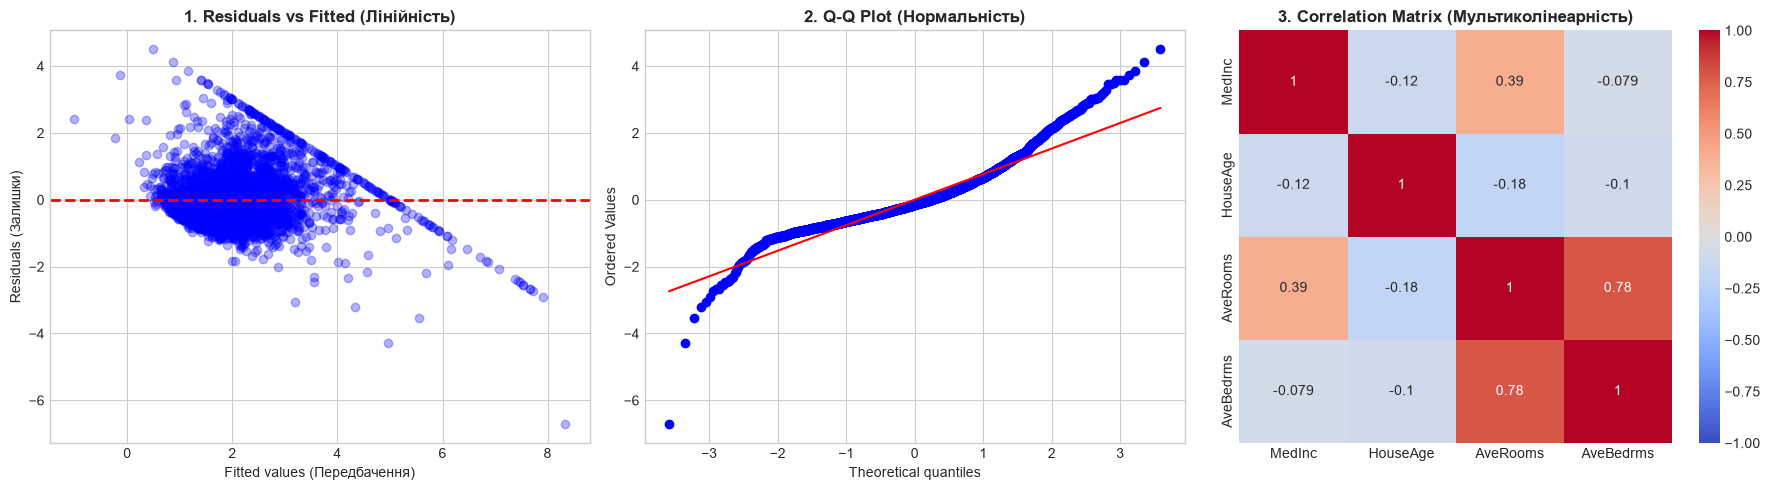

In [8]:
residuals = y_test - y_test_pred

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Лінійність (Residuals vs Fitted)
axes[0].scatter(y_test_pred, residuals, alpha=0.3, color='blue')
axes[0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0].set_title('1. Residuals vs Fitted (Лінійність)', fontweight='bold')
axes[0].set_xlabel('Fitted values (Передбачення)')
axes[0].set_ylabel('Residuals (Залишки)')

# 2. Нормальність (Q-Q plot)
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title('2. Q-Q Plot (Нормальність)', fontweight='bold')

# 3. Мультиколінеарність (Матриця кореляцій числових ознак)
corr_matrix = pd.DataFrame(X_train[num_features], columns=num_features).corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=axes[2])
axes[2].set_title('3. Correlation Matrix (Мультиколінеарність)', fontweight='bold')

plt.tight_layout()
plt.show()

Висновки щодо припущень:

Припущення про Лінійність: 
    порушується. На графіку "Residuals vs Fitted" точки не утворюють хаотичну хмару навколо нуля. Ми бачимо чіткі діагональні межі/структуру. Це означає, що реальна залежність у даних має нелінійний характер, який наша лінійна модель зловити не може.

Припущення про Нормальність залишків: 
    порушується. На графіку Q-Q plot точки суттєво відхиляються від червоної лінії на кінцях (важкі хвости). Це свідчить про наявність великої кількості викидів (outliers), на яких модель сильно помиляється.

Припущення про Відсутність мультиколінеарності: 
    частково порушується. На матриці кореляцій ми бачимо високу кореляцію (наприклад, 0.85) між кімнатами (AveRooms) та спальнями (AveBedrms). Вплив: Мультиколінеарність робить ваги $\mathbf{w}$ нестабільними (чутливими до шуму) та ускладнює їх інтерпретацію (важко зрозуміти, яка саме ознака більше впливає на ціну).

Етап 6. Завдання для глибокого розуміння (Експеримент А: Вплив масштабування)
Ми запустимо Mini-batch GD на немасштабованих даних (без стандартизації) і порівняємо з попередніми результатами.

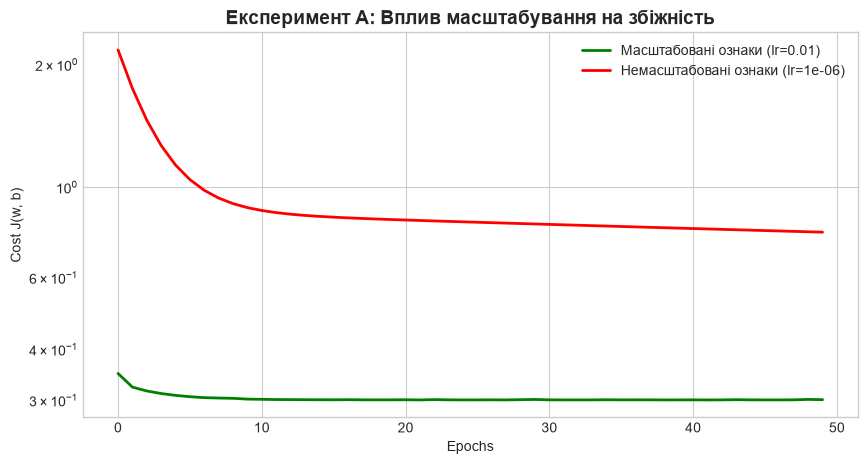

In [9]:
# Експеримент А
# Беремо "сирі" немасштабовані числові ознаки + ohe
X_train_unscaled = np.hstack((X_train[num_features].values, encoded_train))

model_unscaled = NumpyLinearRegression()

# На немасштабованих даних lr=0.01 викличе помилку OverflowError (відхилення до нескінченності).
# Тому ми змушені використати мікроскопічний lr.
lr_unscaled = 1e-6 
model_unscaled.fit(X_train_unscaled, y_train, method='mini-batch', lr=lr_unscaled, epochs=50, batch_size=64)

plt.figure(figsize=(10, 5))
plt.plot(model_mbgd.cost_history, label='Масштабовані ознаки (lr=0.01)', color='green', linewidth=2)
plt.plot(model_unscaled.cost_history, label=f'Немасштабовані ознаки (lr={lr_unscaled})', color='red', linewidth=2)
plt.title('Експеримент А: Вплив масштабування на збіжність', fontsize=14, fontweight='bold')
plt.xlabel('Epochs')
plt.ylabel('Cost J(w, b)')
plt.yscale('log')
plt.legend()
plt.show()

Геометричне пояснення, чому без масштабування GD працює гірше:
Без стандартизації ознаки мають різні масштаби (наприклад, кількість кімнат варіюється від 2 до 10, а дохід від 10000 до 150000). Геометрично, у просторі параметрів (Cost Bowl), функція втрат набуває форми дуже витягнутого, вузького еліпса (схожого на каньйон).

Вектор градієнта в такому каньйоні вказує не безпосередньо до глобального мінімуму, а б'ється об стінки еліпса.

Алгоритм здійснює величезні коливання по вузькій осі, практично не рухаючись по довгій.

Щоб уникнути "градієнтного вибуху" (Gradient Explosion, коли модель розходиться), ми змушені ставити дуже малий Learning Rate (1e-6). Через це модель навчається настільки повільно, що за 50 епох навіть близько не підходить до оптимуму, тоді як модель на масштабованих даних (сферична чаша) збігається майже миттєво.

Загальний висновок

У цій практичній роботі я реалізувала лінійну регресію власними функціями NumPy на датасеті California Housing. Спочатку підготувала дані: розділила їх на Train, Validation і Test (60/20/20) ще до кодування та масштабування, закодувала категоріальну ознаку через One-Hot Encoding і стандартизувала числові ознаки. Параметри енкодера та scaler рахувала тільки на Train, щоб уникнути Data Leakage.

Модель реалізована повністю векторизовано: гіпотеза, функція втрат MSE і градієнти обчислюються матричними операціями без циклів по прикладах. Я порівняла три варіанти градієнтного спуску. Batch GD збігається найстабільніше, SGD дає найбільші коливання, а Mini-batch GD (batch = 64) виявився хорошим компромісом між стабільністю та швидкістю.

Модель отримала R² ≈ 0.55 на Train, 0.53 на Validation і 0.51 на Test. Значення близькі між собою, тож перенавчання немає, але модель пояснює лише приблизно половину розкиду цін. Перевірка статистичних припущень показала, чому так: залежність у даних частково нелінійна, залишки мають важкі хвости (є викиди), а між AveRooms і AveBedrms є сильна кореляція, через що ваги менш стабільні й гірше інтерпретуються.

Експеримент із немасштабованими даними показав, наскільки важлива стандартизація. Без неї функція втрат має форму витягнутого «каньйону», тому доводиться брати дуже малий learning rate (1e-6), і за 50 епох модель навіть не наближається до оптимуму. На масштабованих даних вона збігається майже одразу.

Отже, мету роботи виконано: я реалізувала лінійну регресію з нуля, дослідила різні методи оптимізації та проаналізувала статистичні властивості моделі. Щоб покращити результат, можна було б додати нелінійні (поліноміальні) ознаки, обробити викиди та використати регуляризацію.